# Lab 05 Data visualization with matplotlib and seaborn

Nice visualization libraries:
- matplotlib: https://matplotlib.org/stable/index.html
- seaborn: http://seaborn.pydata.org/
- bokeh: https://docs.bokeh.org/en/latest/
- folium (geospatial visualization): https://python-visualization.github.io/folium/latest/
- kepler.gl (large-scale geospatial visualization): https://kepler.gl/

## Please submit your finished lab05 jupyter notebook via pull request in GitHub

In [1]:
# magic command to display matplotlib plots inline within the ipython notebook webpage
%matplotlib inline

# import necessary modules
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import matplotlib.cm as cm, matplotlib.font_manager as fm

## load the data sets

In [2]:
# load the gps coordinate data, using the date as the full set's index
# the data files are encoded as utf-8: specify so to prevent matplotlib from choking on diacritics
df = pd.read_csv('data/summer-travel-gps-full.csv', encoding='utf-8', index_col='date', parse_dates=True)
rs = pd.read_csv('data/summer-travel-gps-dbscan.csv', encoding='utf-8')

In [4]:
df.head()

,lat,lon,city,country
date,,,,
2014-05-14 09:07:00,51.481292,-0.451011,West Drayton,United Kingdom
2014-05-14 09:22:00,51.474005,-0.450999,Hounslow,United Kingdom
2014-05-14 10:51:00,51.478199,-0.446081,Hounslow,United Kingdom
2014-05-14 11:24:00,51.478199,-0.446081,Hounslow,United Kingdom
2014-05-14 11:38:00,51.474146,-0.451562,Hounslow,United Kingdom


In [5]:
rs.head()

,lat,lon,date,city,country
0,51.478199,-0.446081,05/14/2014 10:51,Hounslow,United Kingdom
1,38.781775,-9.137544,05/14/2014 15:11,Lisbon,Portugal
2,38.771939,-9.128911,05/14/2014 15:41,Lisbon,Portugal
3,38.742987,-9.147780,05/14/2014 16:11,Lisbon,Portugal
4,38.693780,-9.206363,05/15/2014 14:19,Lisbon,Portugal


## First up: Bar Charts

In [6]:
# Q1: Can you draw a bar chart for the most visited countries by using matplotlib and seaborn? You can use the df dataframe.
# Please style the chart to make it look nicer
# such as figsize, width, alpha, color, edgecolor, grid, xlim, and ylim

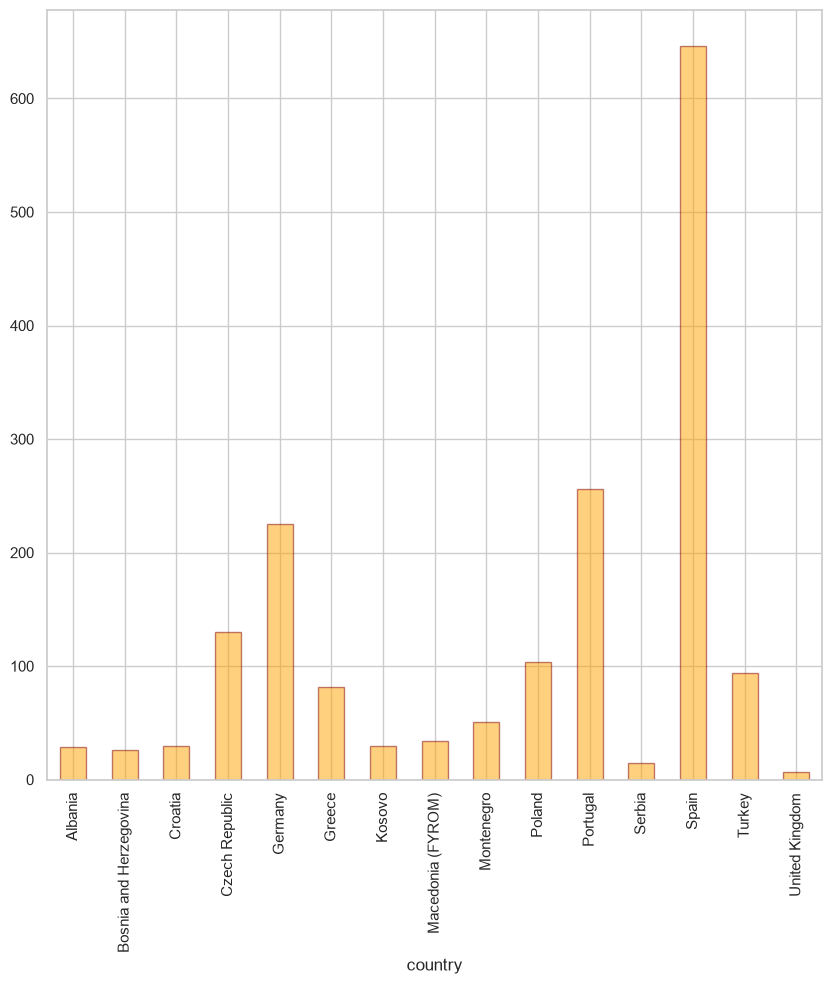

In [39]:
countrycount= df.groupby('country')['country'].count()
countrycount.plot(kind='bar', figsize= (10,10), alpha = (0.5), color='orange', edgecolor='maroon')
plt.show()

Now you try: re-create the plot above, but make the bars orange with maroon edges.

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 [Text(0, 0, 'Albania'),
  Text(1, 0, 'Bosnia and Herzegovina'),
  Text(2, 0, 'Croatia'),
  Text(3, 0, 'Czech Republic'),
  Text(4, 0, 'Germany'),
  Text(5, 0, 'Greece'),
  Text(6, 0, 'Kosovo'),
  Text(7, 0, 'Macedonia (FYROM)'),
  Text(8, 0, 'Montenegro'),
  Text(9, 0, 'Poland'),
  Text(10, 0, 'Portugal'),
  Text(11, 0, 'Serbia'),
  Text(12, 0, 'Spain'),
  Text(13, 0, 'Turkey'),
  Text(14, 0, 'United Kingdom')])

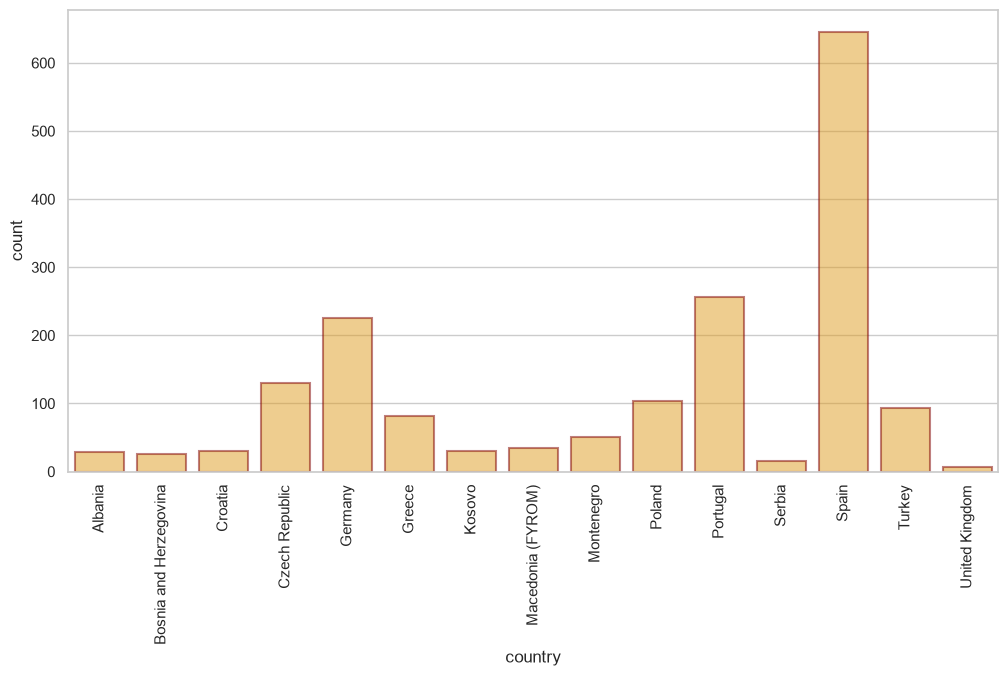

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt
countrycount2 = df.groupby('country')['country'].count().reset_index(name='count')
sns.set_style("whitegrid")
plt.figure(figsize=(12, 6))
sns.barplot(
    x="country",
    y="count",
    data=countrycount,
    alpha= (0.5),
    color="orange",
    edgecolor="maroon",
    linewidth=1.5
)
plt.xticks(rotation=90)


In [7]:
# Q2: Draw the same bar chart, but now for the most visited cities instead of countries

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  72,
  73,
  74,
  75,
  76,
  77,
  78,
  79,
  80,
  81,
  82,
  83,
  84,
  85,
  86,
  87,
  88,
  89,
  90,
  91,
  92,
  93,
  94,
  95,
  96,
  97,
  98,
  99,
  100,
  101,
  102,
  103,
  104,
  105,
  106,
  107,
  108,
  109,
  110,
  111,
  112],
 [Text(0, 0, 'Algueirão-Mem Martins'),
  Text(1, 0, 'Alpirsbach'),
  Text(2, 0, 'Amadora'),
  Text(3, 0, 'Ansbach'),
  Text(4, 0, 'Athens'),
  Text(5, 0, 'Attica'),
  Text(6, 0, 'Aveiro District'),
  Text(7, 0, 'Azambuja'),
  Text(8, 0, 'Babice, Oświęcim County'),
  Text(9, 0, 'Balice, Lesser Poland Voivodeship'),
  

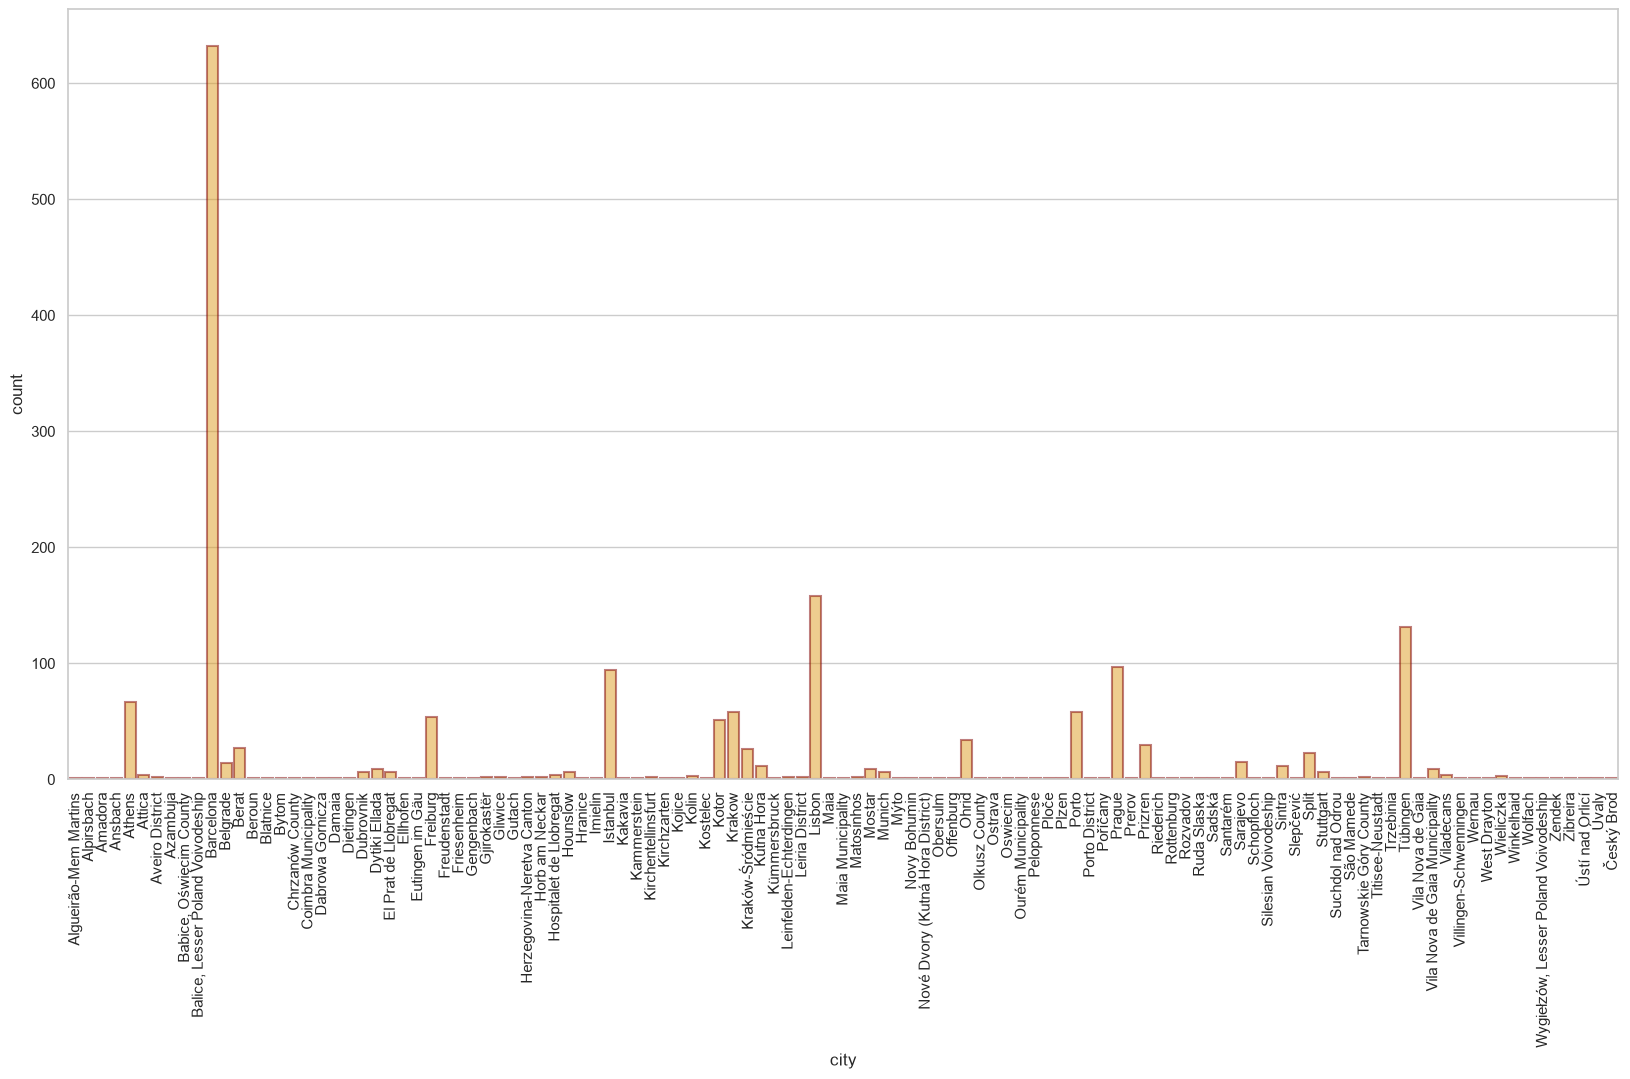

In [51]:
citycount = df.groupby('city')['city'].count().reset_index(name='count')
sns.set_style("whitegrid")
plt.figure(figsize=(20, 10))
sns.barplot(
    x="city",
    y="count",
    data=citycount,
    alpha= (0.5),
    color="orange",
    edgecolor="maroon",
    linewidth=1.5
)
plt.xticks(rotation=90)

## Next: scatter plots as simple maps

In [8]:
# Q3: Draw a scatter plot the longitude and latitude data, with matplotlib and seaborn defaults. 
# You can use the rs dataframe.
# Please style the chart to make it look nicer with good size and alpha settings. 

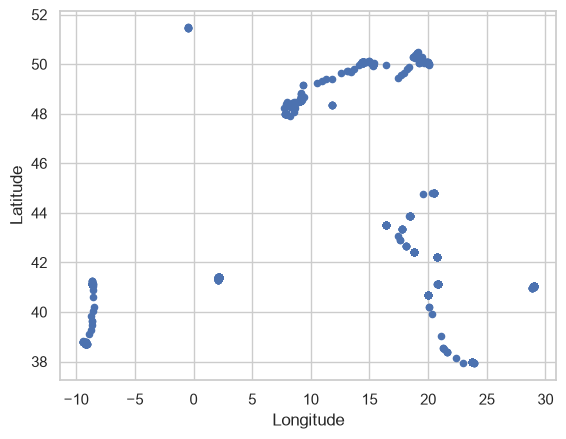

In [62]:
datascatter = df[['lon', 'lat']]

datascatter.plot(kind='scatter', x='lon', y='lat')

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

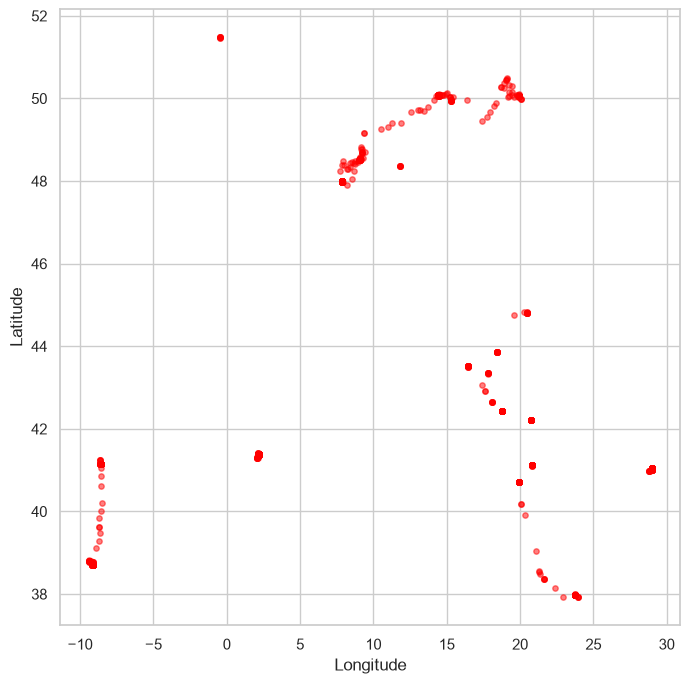

In [67]:
datascatter.plot(kind='scatter', x='lon', y='lat', figsize=(8, 8), color='red', alpha=0.5, s=15)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

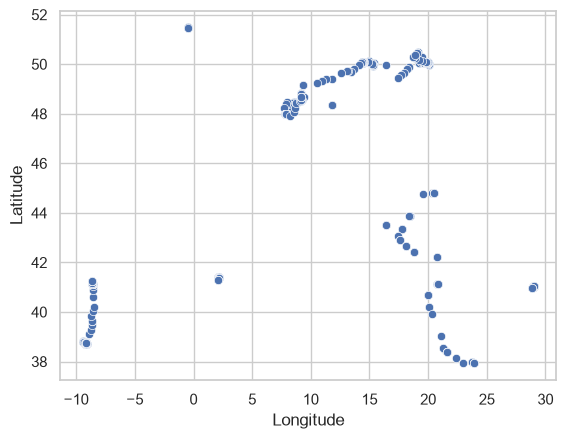

In [78]:
sns.set_style("whitegrid")

sns.scatterplot(x="lon", y="lat", data=datascatter)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

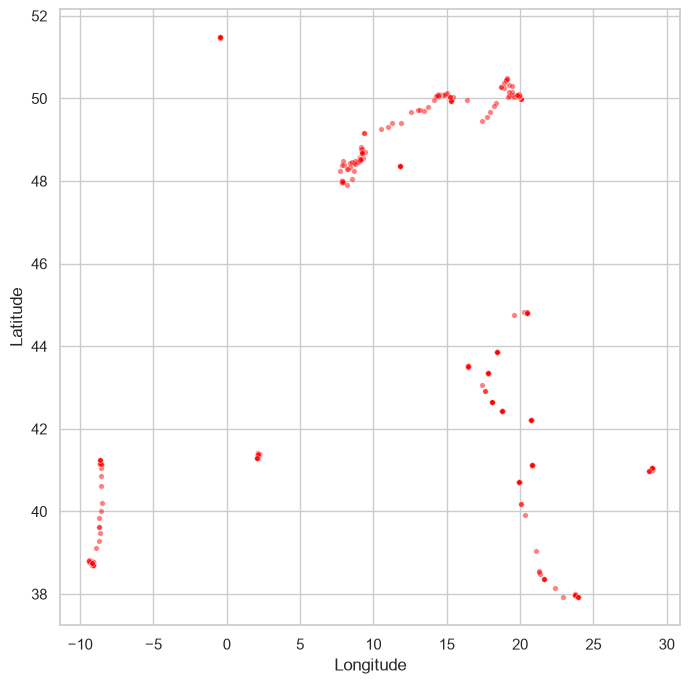

In [80]:
sns.set_style("whitegrid")

plt.figure(figsize=(8, 8))

sns.scatterplot( x="lon", y="lat", data=datascatter, color='red', alpha=0.5, s=15)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

## Line charts, with annotation

In [84]:
# get the count of records by date
countdata = df.groupby(df.index.date).size()
countdata.head()

2014-05-14    36
2014-05-15    61
2014-05-16    57
2014-05-17    64
2014-05-18    50
dtype: int64

In [10]:
# Q4: Draw a  matplotlib and seaborn line chart from countdata. 
# Please style the chart to make it look nicer with good size and alpha settings. 

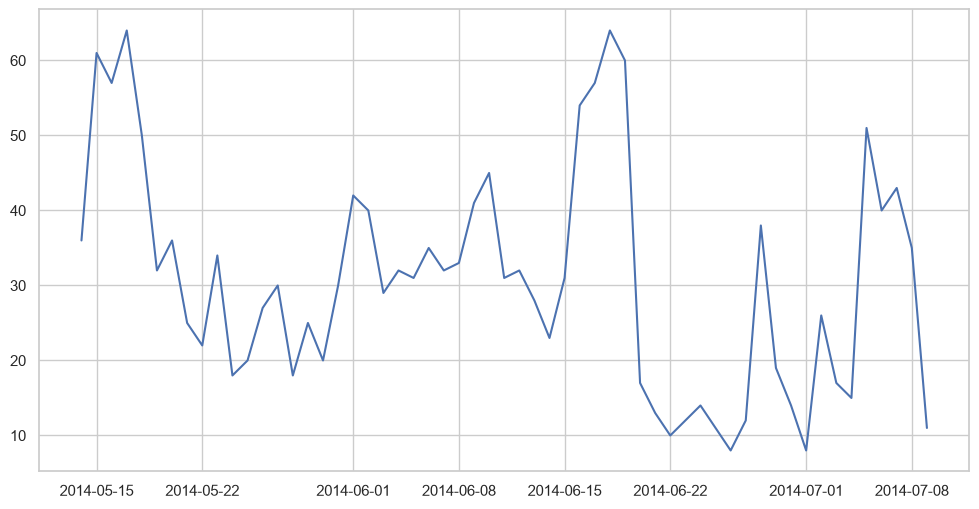

In [89]:
countdata = df.groupby(df.index.date).size()
countdata.plot(figsize=(12, 6))
plt.show()

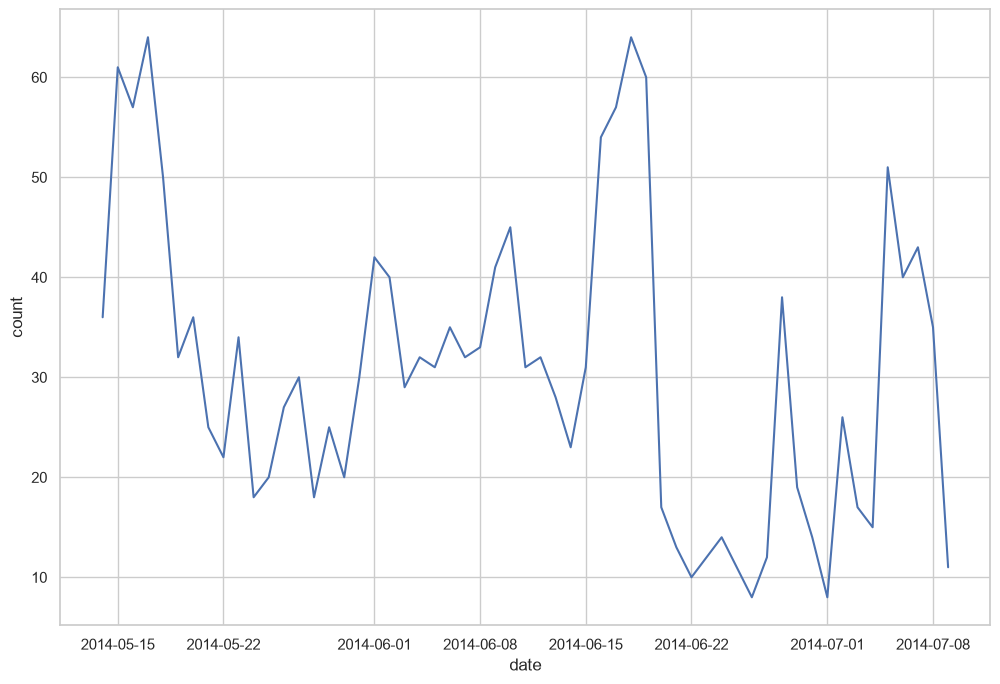

In [96]:
import seaborn as sns
import matplotlib.pyplot as plt

countdata = df.groupby(df.index.date).size().reset_index(name='count')
countdata.columns = ['date', 'count']

sns.set_style("whitegrid")
plt.figure(figsize=(12, 8))

sns.lineplot( data=countdata, x="date", y="count")
plt.show()

In [11]:
# Q5: Now you try: re-create the plot above with different line widths, colors, and point markers. 
# Play with moving the annotation labels around. Make the vertical tick marks 3 days apart instead of 5.
# experiment with a more advanced challenge like smoothing the line:
# - https://stackoverflow.com/questions/5283649/plot-smooth-line-with-pyplot
# - https://stackoverflow.com/questions/25825946/generating-smooth-line-graph-using-matplotlib

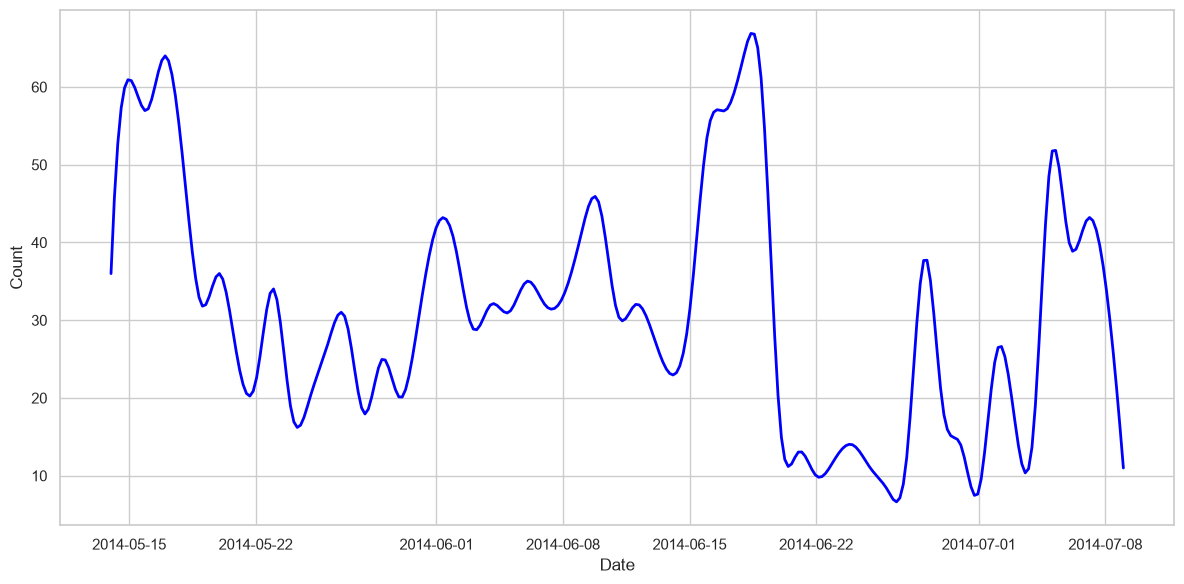

In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline

countdata = df.groupby(df.index.date).size().reset_index(name='count')
countdata.columns = ['date', 'count']

countdata['date'] = pd.to_datetime(countdata['date'])

x = (countdata['date'] - countdata['date'].min()).dt.days.to_numpy()
y = countdata['count'].to_numpy()

x_smooth = np.linspace(x.min(), x.max(), 300)

spl = make_interp_spline(x, y, k=min(3, len(x)-1))
y_smooth = spl(x_smooth)

dates_smooth = countdata['date'].min() + pd.to_timedelta(x_smooth, unit='D')


plt.figure(figsize=(12, 6))


plt.plot(dates_smooth, y_smooth, color='blue', linewidth=2)

plt.xlabel('Date')
plt.ylabel('Count')
plt.grid(True)
plt.tight_layout()
plt.show()

## Pie charts

In [115]:
cities = df['city'].value_counts()
print(cities.count())
cities.head()

113


city
Barcelona    632
Lisbon       158
Tübingen     131
Prague        97
Istanbul      94
Name: count, dtype: int64

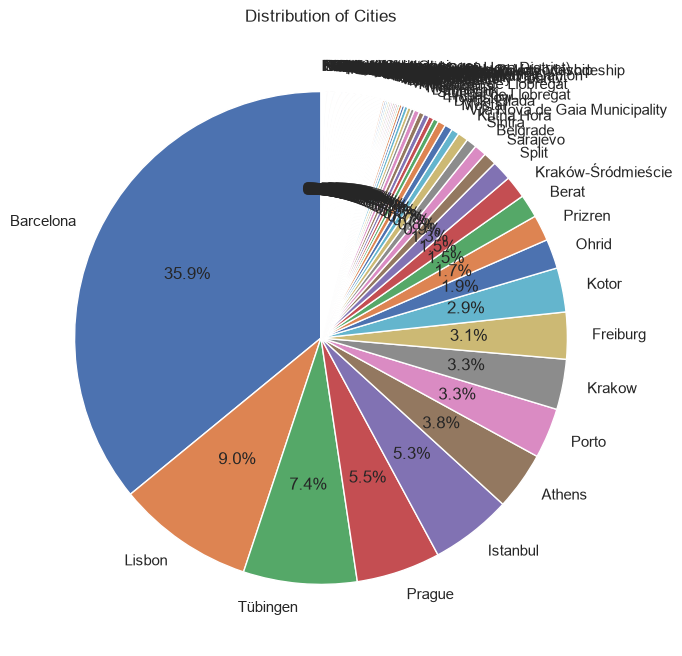

In [151]:
cities = df['city'].value_counts()

# Set figure size
plt.figure(figsize=(8, 8))

# Create pie chart
plt.pie(
    cities,
    labels=cities.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Distribution of Cities")
plt.show()

In [13]:
# Q6: draw a pie chart for cities.
# Please style the chart to make it look nicer. 

## Extra task: Kepler.gl
Some examples: https://docs.kepler.gl/docs/keplergl-jupyter and https://jamesopacich.medium.com/display-a-kepler-gl-map-69d807dae082

In [14]:
# Q7: can you visualize the GPS points by using Kepler.gl? 


In [157]:
%pip install keplergl

Note: you may need to restart the kernel to use updated packages.


In [162]:
%pip install --upgrade anywidget ipywidgets jupyterlab_widgets

  Using cached ipywidgets-8.1.9-py3-none-any.whl.metadata (2.4 kB)
  Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl.metadata (20 kB)
  Using cached widgetsnbextension-4.0.16-py3-none-any.whl.metadata (1.6 kB)
Using cached ipywidgets-8.1.9-py3-none-any.whl (140 kB)
Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl (217 kB)
Using cached widgetsnbextension-4.0.16-py3-none-any.whl (2.2 MB)

  Attempting uninstall: widgetsnbextension

    Found existing installation: widgetsnbextension 4.0.14

    Uninstalling widgetsnbextension-4.0.14:

      Successfully uninstalled widgetsnbextension-4.0.14

   ---------------------------------------- 0/3 [widgetsnbextension]
  Attempting uninstall: jupyterlab_widgets
   ---------------------------------------- 0/3 [widgetsnbextension]
    Found existing installation: jupyterlab_widgets 3.0.16
   ---------------------------------------- 0/3 [widgetsnbextension]
    Uninstalling jupyterlab_widgets-3.0.16:
   --------------------------------

In [164]:
import importlib.metadata as md

for package in [
    "jupyterlab",
    "keplergl",
    "anywidget",
    "ipywidgets",
    "jupyterlab_widgets"
]:
    print(package, md.version(package))

jupyterlab 4.5.9
keplergl 0.4.0
anywidget 0.11.0
ipywidgets 8.1.9
jupyterlab_widgets 3.0.17


In [165]:
from keplergl import KeplerGl
import pandas as pd
import json

gps = pd.read_csv("data/summer-travel-kepler-ready.csv")
legs = pd.read_csv("data/summer-travel-legs.csv")

with open("data/summer-travel-kepler-config.json") as f:
    config = json.load(f)

travel_map = KeplerGl(
    height=650,
    data={
        "gps": gps,
        "legs": legs
    },
    config=config
)

travel_map


In [166]:
travel_map.save_to_html(
    file_name="summer_travel_map.html",
    read_only=False
)

Map saved to summer_travel_map.html!
